In [2]:
# Step 1: Data Ingestion
# Install yfinance if you are using Google Colab by running: !pip install yfinance

import yfinance as yf
import pandas as pd

# 1. Define a diversified basket of stocks (Tickers)
# We select companies across different sectors (Tech, Finance, Healthcare, Retail, Energy)
tickers = ['AAPL', 'MSFT', 'JPM', 'JNJ', 'WMT', 'PG', 'XOM', 'TSLA']

# 2. Define the timeframe (Last ~5 years)
start_date = "2021-01-01"
end_date = "2026-11-01"

print(f"Downloading data for {len(tickers)} tickers from {start_date} to {end_date}...")

# 3. Download the data
# We set auto_adjust=False to guarantee that 'Adj Close' is downloaded separately from 'Close'
raw_data = yf.download(tickers, start=start_date, end=end_date, auto_adjust=False)['Adj Close']

# 4. Clean the data
# Forward-fill (ffill) handles missing values (e.g., if a stock was halted or market holidays differ)
# Dropna removes any remaining rows with NaN values at the very beginning
clean_data = raw_data.ffill().dropna()

print("\n--- Data Ingestion Complete ---")
print(f"Dataset dimensions: {clean_data.shape[0]} trading days, {clean_data.shape[1]} assets.")
print("\nFirst 3 rows of our dataset:")
print(clean_data.head(3))

[******************    38%                       ]  3 of 8 completed

[*********************100%***********************]  8 of 8 completed



--- Data Ingestion Complete ---
Dataset dimensions: 1464 trading days, 8 assets.

First 3 rows of our dataset:
Ticker            AAPL         JNJ         JPM        MSFT          PG  \
Date                                                                     
2021-01-04  125.632523  133.628326  108.459442  207.565384  118.183205   
2021-01-05  127.185776  135.199417  109.049591  207.765610  118.937782   
2021-01-06  122.904518  136.471664  114.170120  202.378357  120.189781   

Ticker            TSLA        WMT        XOM  
Date                                          
2021-01-04  243.256668  45.345741  33.251324  
2021-01-05  245.036667  45.104359  34.853806  
2021-01-06  251.993332  45.385975  35.743168  


In [3]:
# Step 2: Financial Feature Engineering
import numpy as np

print("Calculating financial metrics (Returns, Volatility, Covariance)...")

# 1. Calculate Daily Percentage Returns
# ML models and optimization algorithms require stationary data (returns), not absolute prices.
daily_returns = clean_data.pct_change().dropna()

# 2. Calculate Annualized Expected Returns
# We assume 252 trading days in a year.
# This tells us the average yearly performance of each stock based on historical data.
annual_returns = daily_returns.mean() * 252

# 3. Calculate Annualized Volatility (Risk)
# Volatility is the standard deviation of returns. We scale it to an annual metric using sqrt(252).
annual_volatility = daily_returns.std() * np.sqrt(252)

# 4. Calculate the Annualized Covariance Matrix
# Crucial for Markowitz Portfolio Theory: measures how asset prices move in relation to one another.
cov_matrix = daily_returns.cov() * 252

# 5. Combine Returns and Risk into a single summary DataFrame
asset_metrics = pd.DataFrame({
    'Expected Annual Return': annual_returns,
    'Annual Volatility': annual_volatility
})

print("\n--- Feature Engineering Complete ---")
print("\nAsset Risk/Return Profile:")
print(asset_metrics.round(4)) # Rounded for better readability

Calculating financial metrics (Returns, Volatility, Covariance)...

--- Feature Engineering Complete ---

Asset Risk/Return Profile:
        Expected Annual Return  Annual Volatility
Ticker                                           
AAPL                    0.2117             0.2756
JNJ                     0.1385             0.1748
JPM                     0.2240             0.2395
MSFT                    0.1957             0.2721
PG                      0.0699             0.1791
TSLA                    0.2571             0.5874
WMT                     0.1966             0.2183
XOM                     0.3347             0.2712


Applying K-Means Clustering to discover asset groups...

Assets mapped to their respective clusters:
        Expected Annual Return  Annual Volatility  Cluster
Ticker                                                    
AAPL                    0.2117             0.2756        0
JNJ                     0.1385             0.1748        2
JPM                     0.2240             0.2395        0
MSFT                    0.1957             0.2721        0
PG                      0.0699             0.1791        2
TSLA                    0.2571             0.5874        1
WMT                     0.1966             0.2183        0
XOM                     0.3347             0.2712        0


/tmp/ipykernel_3197/34966743.py:48: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  asset_metrics['Annual Volatility'][i] + 0.005,
/tmp/ipykernel_3197/34966743.py:49: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  asset_metrics['Expected Annual Return'][i],


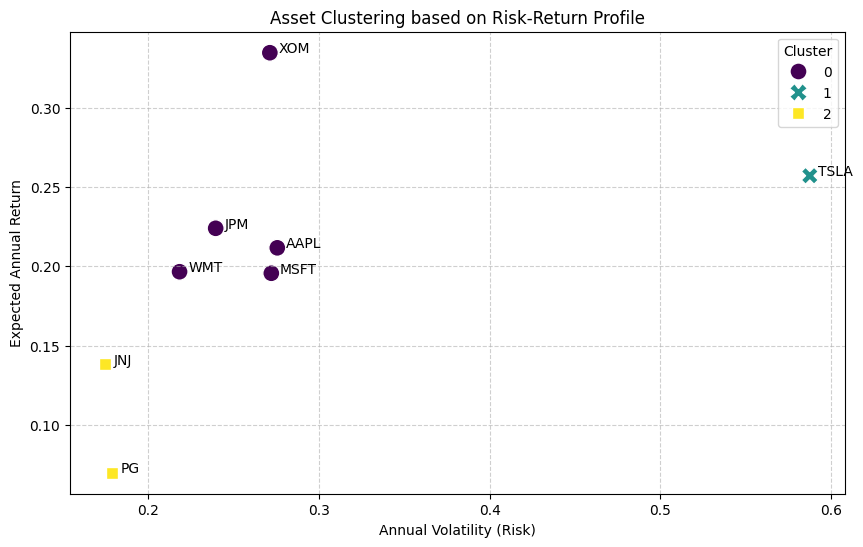


--- Machine Learning Clustering Complete ---


In [4]:
# Step 3: Machine Learning - K-Means Clustering
# Install required libraries if needed: !pip install scikit-learn matplotlib seaborn

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

print("Applying K-Means Clustering to discover asset groups...")

# 1. Prepare features for the ML model
# We use Expected Annual Return and Annual Volatility as our features (X)
X = asset_metrics[['Annual Volatility', 'Expected Annual Return']]

# 2. Scale the data (Crucial for distance-based algorithms like K-Means)
# Standardizes features by removing the mean and scaling to unit variance
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Apply K-Means Algorithm
# We choose 3 clusters to find distinct Risk/Return profiles
# (e.g., Conservative, Moderate, Aggressive)
# random_state ensures reproducibility of the results
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(X_scaled)

# 4. Assign the cluster labels back to our dataframe
asset_metrics['Cluster'] = kmeans.labels_

print("\nAssets mapped to their respective clusters:")
print(asset_metrics[['Expected Annual Return', 'Annual Volatility', 'Cluster']].round(4))

# 5. Visualize the Clusters
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=asset_metrics,
    x='Annual Volatility',
    y='Expected Annual Return',
    hue='Cluster',
    palette='viridis',
    s=150, # size of the points
    style='Cluster'
)

# Add ticker labels to each point
for i in range(asset_metrics.shape[0]):
    plt.text(
        asset_metrics['Annual Volatility'][i] + 0.005,
        asset_metrics['Expected Annual Return'][i],
        asset_metrics.index[i],
        fontsize=10
    )

plt.title('Asset Clustering based on Risk-Return Profile')
plt.xlabel('Annual Volatility (Risk)')
plt.ylabel('Expected Annual Return')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print("\n--- Machine Learning Clustering Complete ---")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [PyPortfolioOpt]
Calculating the optimal portfolio weights based on the Efficient Frontier...

--- Optimal Portfolio Allocation ---
AAPL: 0.73%
JNJ: 17.47%
JPM: 10.71%
MSFT: 12.89%
WMT: 20.18%
XOM: 38.01%

Expected Portfolio Performance:
Expected annual return: 23.9%
Annual volatility: 14.8%
Sharpe Ratio: 1.42


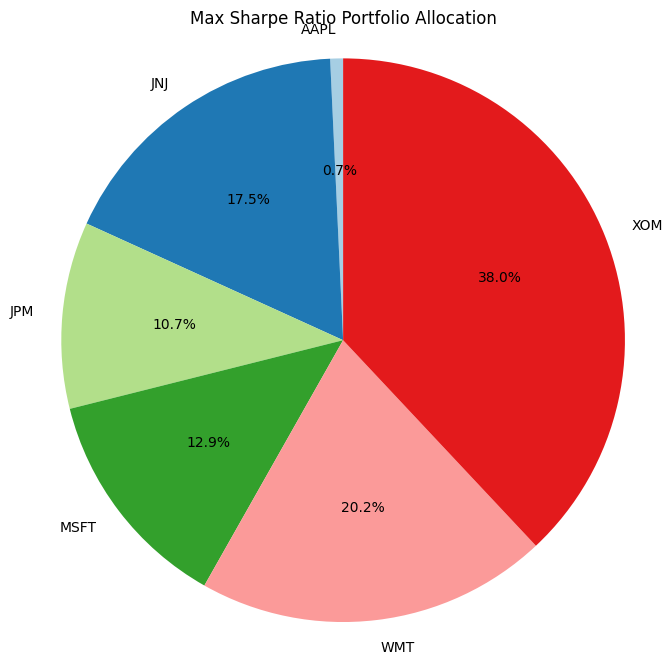


--- Optimization Complete ---


In [6]:
# Step 4: Portfolio Optimization (Markowitz Efficient Frontier)
# Install standard dependency directly
!pip install PyPortfolioOpt

from pypfopt.efficient_frontier import EfficientFrontier
from pypfopt import risk_models
from pypfopt import expected_returns
import matplotlib.pyplot as plt

print("Calculating the optimal portfolio weights based on the Efficient Frontier...")

# 1. Recalculate Expected Returns and Sample Covariance
# PyPortfolioOpt has built-in functions that calculate these metrics more robustly
# (e.g., using exponential moving averages instead of simple historical means)
mu = expected_returns.mean_historical_return(clean_data)
S = risk_models.sample_cov(clean_data)

# 2. Setup the Efficient Frontier Model
# We set weight_bounds=(0, 1) meaning we only allow 'Long' positions (no short selling)
ef = EfficientFrontier(mu, S, weight_bounds=(0, 1))

# 3. Optimize for the Maximum Sharpe Ratio
# The Sharpe ratio measures the performance of an investment compared to a risk-free asset,
# after adjusting for its risk.
weights = ef.max_sharpe(risk_free_rate=0.03) # Assuming a 3% risk-free rate (e.g., Treasury yield)

# 4. Clean and print the weights
# ef.clean_weights() removes very tiny weights (e.g., 0.00001) and rounds them to 0.
cleaned_weights = ef.clean_weights()

print("\n--- Optimal Portfolio Allocation ---")
for ticker, weight in cleaned_weights.items():
    if weight > 0:
        # Multiply by 100 to show percentage
        print(f"{ticker}: {weight * 100:.2f}%")

# 5. Display the expected portfolio performance metrics
print("\nExpected Portfolio Performance:")
ef.portfolio_performance(verbose=True, risk_free_rate=0.03)

# 6. Visualize the Allocation with a Pie Chart
labels = [ticker for ticker, weight in cleaned_weights.items() if weight > 0]
sizes = [weight for ticker, weight in cleaned_weights.items() if weight > 0]

plt.figure(figsize=(8, 8))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90, colors=plt.cm.Paired.colors)
plt.title('Max Sharpe Ratio Portfolio Allocation')
plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

print("\n--- Optimization Complete ---")

Simulating portfolio performance over the historical period...

--- Backtest Results ---
Initial Investment: €10,000.00
Final Value: €24,825.08
Total Return: 148.25%
Maximum Drawdown: -18.32%


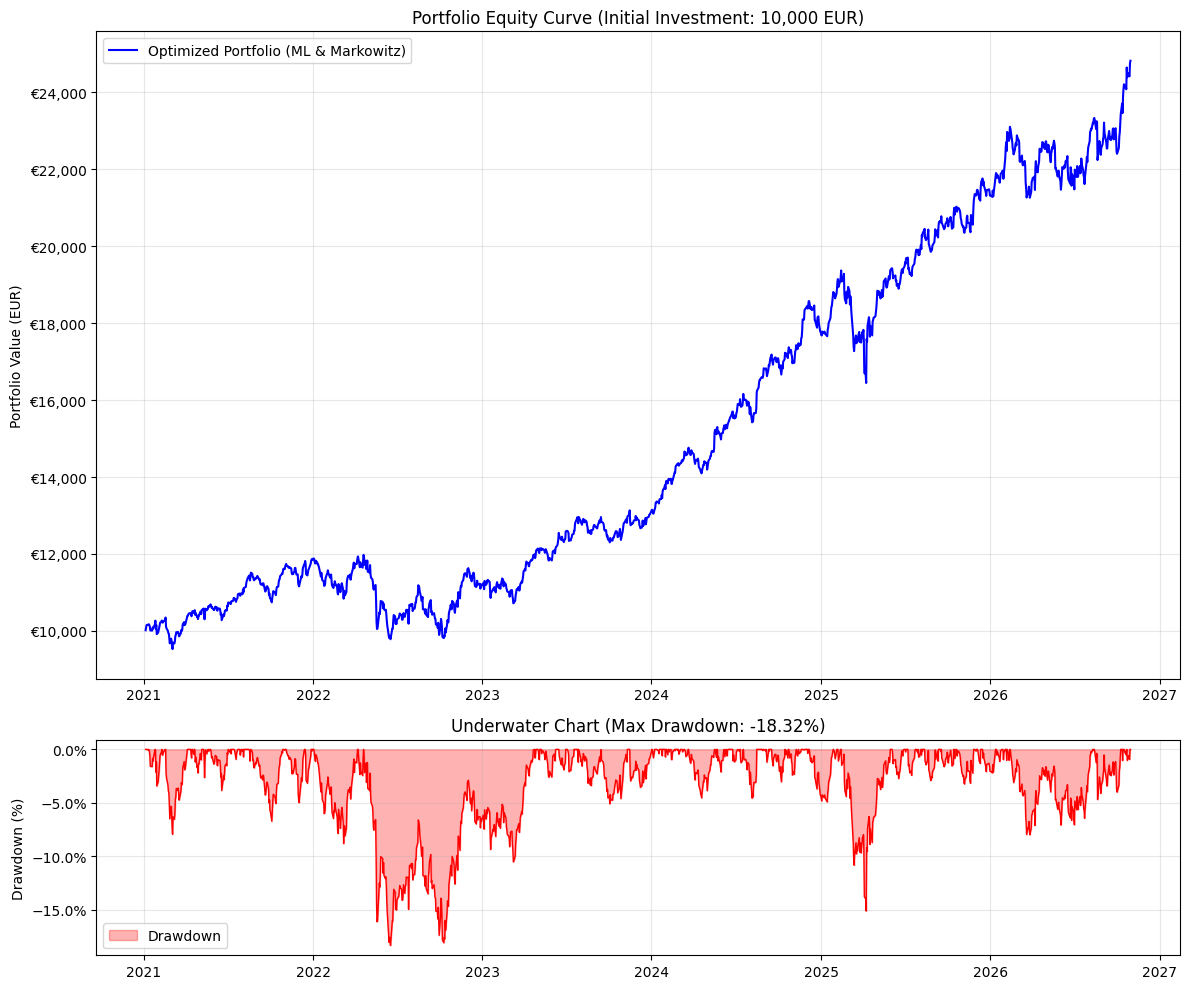


--- Project Completed Successfully ---


In [7]:
# Step 5: Backtesting and Business Metrics
import matplotlib.ticker as mtick

print("Simulating portfolio performance over the historical period...")

# 1. Prepare the Portfolio Allocation
# We extract the non-zero weights from the previous optimization
portfolio_weights = np.array([cleaned_weights[ticker] for ticker in tickers])

# 2. Calculate Daily Portfolio Returns
# We multiply the daily returns of each stock by its optimized weight in the portfolio
# Then we sum across columns (axis=1) to get the daily total portfolio return
portfolio_daily_returns = (daily_returns * portfolio_weights).sum(axis=1)

# 3. Calculate Cumulative Growth (Base 10,000 EUR)
# If we invested 10,000 at the start date, how did it grow over time?
initial_investment = 10000
# cumulative product of (1 + daily_return) gives the growth factor
cumulative_growth = initial_investment * (1 + portfolio_daily_returns).cumprod()

# 4. Calculate Maximum Drawdown
# This is the single most important metric for risk managers:
# "What is the largest drop from a peak to a trough before a new peak is achieved?"
rolling_max = cumulative_growth.cummax()
drawdown = cumulative_growth / rolling_max - 1
max_drawdown = drawdown.min()

print("\n--- Backtest Results ---")
print(f"Initial Investment: €{initial_investment:,.2f}")
print(f"Final Value: €{cumulative_growth.iloc[-1]:,.2f}")
total_return_pct = (cumulative_growth.iloc[-1] / initial_investment - 1) * 100
print(f"Total Return: {total_return_pct:.2f}%")
print(f"Maximum Drawdown: {max_drawdown * 100:.2f}%")

# 5. Visualize the Backtest
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), gridspec_kw={'height_ratios': [3, 1]})

# Top Chart: Portfolio Equity Curve
ax1.plot(cumulative_growth.index, cumulative_growth, label='Optimized Portfolio (ML & Markowitz)', color='blue')
ax1.set_title('Portfolio Equity Curve (Initial Investment: 10,000 EUR)')
ax1.set_ylabel('Portfolio Value (EUR)')
ax1.grid(True, alpha=0.3)
ax1.legend()
# Format y-axis as currency
fmt = '€{x:,.0f}'
tick = mtick.StrMethodFormatter(fmt)
ax1.yaxis.set_major_formatter(tick)

# Bottom Chart: Underwater Curve (Drawdown)
ax2.fill_between(drawdown.index, drawdown, 0, color='red', alpha=0.3, label='Drawdown')
ax2.plot(drawdown.index, drawdown, color='red', linewidth=1)
ax2.set_title(f'Underwater Chart (Max Drawdown: {max_drawdown*100:.2f}%)')
ax2.set_ylabel('Drawdown (%)')
ax2.grid(True, alpha=0.3)
ax2.legend()
# Format y-axis as percentage
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

plt.tight_layout()
plt.show()

print("\n--- Project Completed Successfully ---")

[*********************100%***********************]  8 of 8 completed
/usr/local/lib/python3.13/dist-packages/pypfopt/efficient_frontier/efficient_frontier.py:259: UserWarning: max_sharpe transforms the optimization problem so additional objectives may not work as expected.
  warnings.warn(



--- Allocazione Ottimale (AI_Boom) con Cap al 30.0% ---
AMD: 5.00%
AMZN: 5.00%
ASML: 5.00%
GOOGL: 22.35%
MSFT: 19.52%
NVDA: 30.00%
PLTR: 8.13%
TSM: 5.00%

 RISULTATI OUT-OF-SAMPLE: AI_Boom
Periodo Test: 2024-12-31 -> 2026-10-30
Capitale Iniziale: €10,000.00
Capitale Finale: €17,692.67
Rendimento Totale: 76.93%
Max Drawdown: -26.10%


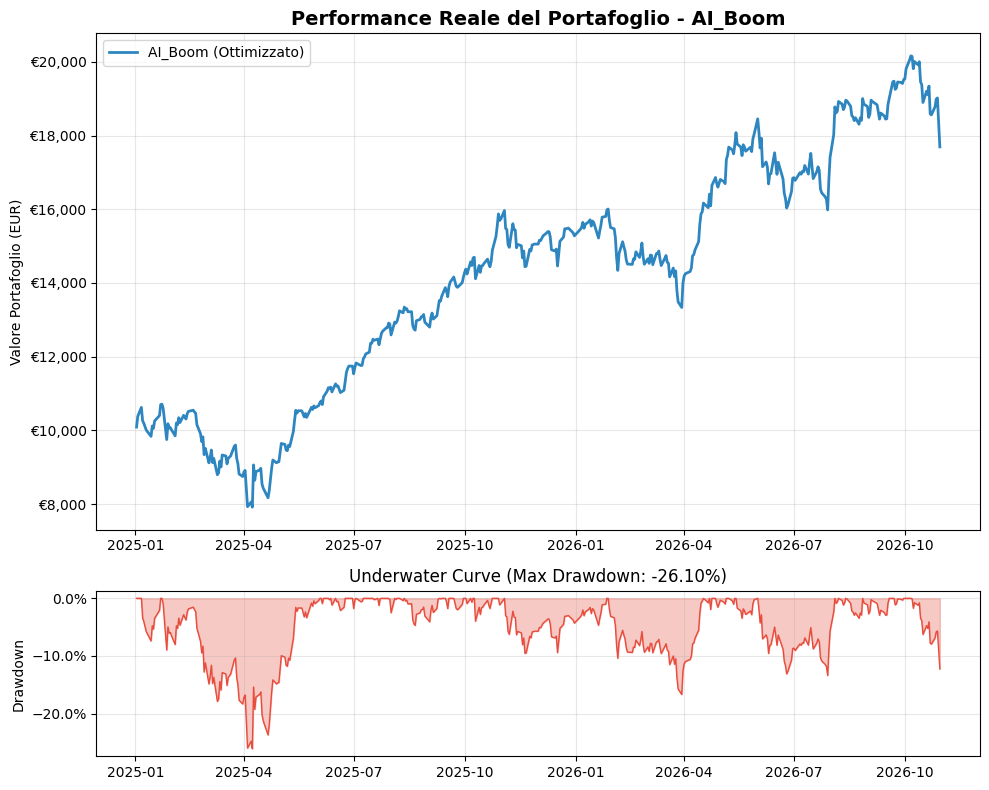

In [11]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from pypfopt import risk_models, expected_returns
from pypfopt.efficient_frontier import EfficientFrontier
import logging

# 1. Setup del sistema di logging aziendale (sostituisce i semplici print)
logging.basicConfig(level=logging.INFO, format='%(levelname)s - %(message)s')

# 2. Refactoring OOP: Creazione della Classe Principale
class QuantPortfolio:
    def __init__(self, theme_name, tickers, train_start, train_end, test_end, initial_capital=10000):
        self.theme_name = theme_name
        self.tickers = tickers
        self.train_start = train_start
        self.train_end = train_end
        self.test_end = test_end
        self.initial_capital = initial_capital

        # Inizializziamo i DataFrame vuoti che verranno riempiti dai metodi
        self.train_data = pd.DataFrame()
        self.test_data = pd.DataFrame()
        self.weights = {}

    def fetch_and_split_data(self):
        logging.info(f"Avvio estrazione dati per il portafoglio: {self.theme_name}")

        # 3. Gestione degli Errori (Robustness)
        try:
            # yf.download scarica i dati. Impostiamo auto_adjust=False per garantire la presenza di 'Adj Close'
            raw_data = yf.download(self.tickers, start=self.train_start, end=self.test_end, auto_adjust=False)['Adj Close']
            raw_data = raw_data.dropna(axis=1, how='all')
            clean_data = raw_data.ffill().dropna()

            if clean_data.empty:
                raise ValueError("Nessun dato scaricato. Verifica la connessione o i Ticker.")

            # 4. ELIMINAZIONE LOOK-A-HEAD BIAS: Train/Test Split temporale
            self.train_data = clean_data.loc[:self.train_end]
            self.test_data = clean_data.loc[self.train_end:]

            logging.info(f"Split completato. Dati In-Sample (Train): {len(self.train_data)} giorni. Dati Out-of-Sample (Test): {len(self.test_data)} giorni.")

        except Exception as e:
            logging.error(f"Errore critico durante l'estrazione dati: {e}")

    def optimize_weights(self, max_weight=0.30, min_weight=0.05):
        logging.info("Calcolo frontiera efficiente sui dati IN-SAMPLE (Passato)...")
        if self.train_data.empty:
            logging.error("Dati di training mancanti. Eseguire fetch_and_split_data().")
            return

        mu = expected_returns.mean_historical_return(self.train_data)
        S = risk_models.sample_cov(self.train_data)

        # LA SOLUZIONE: Vincoliamo i pesi (min 5%, max 30% per singola azione)
        # Questo impedisce al modello di "innamorarsi" solo di NVIDIA
        ef = EfficientFrontier(mu, S, weight_bounds=(min_weight, max_weight))

        # Opzionale: aggiungiamo una penalizzazione (L2 Regularization) per forzare un'ulteriore diversificazione
        from pypfopt import objective_functions
        ef.add_objective(objective_functions.L2_reg, gamma=0.1)

        raw_weights = ef.max_sharpe(risk_free_rate=0.03)
        self.weights = ef.clean_weights()

        print(f"\n--- Allocazione Ottimale ({self.theme_name}) con Cap al {max_weight*100}% ---")
        for ticker, weight in self.weights.items():
            if weight > 0:
                print(f"{ticker}: {weight*100:.2f}%")

        return self.weights

    def run_backtest(self):
        logging.info("Avvio simulazione sui dati OUT-OF-SAMPLE (Futuro non visto)...")
        if self.test_data.empty or not self.weights:
            logging.error("Dati di test o pesi mancanti.")
            return

        # 5. Vettorializzazione Avanzata (Zero cicli for)
        daily_returns = self.test_data.pct_change().dropna()

        # Allineiamo i pesi alle colonne del dataset
        weight_array = np.array([self.weights.get(ticker, 0.0) for ticker in daily_returns.columns])

        # Prodotto Scalare (Dot Product): Moltiplica e somma l'intera matrice istantaneamente
        portfolio_daily_returns = daily_returns.dot(weight_array)

        # Calcolo vettorializzato della crescita
        cumulative_growth = self.initial_capital * (1 + portfolio_daily_returns).cumprod()

        # Calcolo vettorializzato del Drawdown
        rolling_max = cumulative_growth.cummax()
        drawdown = cumulative_growth / rolling_max - 1
        max_drawdown = drawdown.min()

        final_value = cumulative_growth.iloc[-1]
        total_return = (final_value / self.initial_capital - 1) * 100

        print("\n========================================")
        print(f" RISULTATI OUT-OF-SAMPLE: {self.theme_name}")
        print("========================================")
        print(f"Periodo Test: {self.test_data.index[0].date()} -> {self.test_data.index[-1].date()}")
        print(f"Capitale Iniziale: €{self.initial_capital:,.2f}")
        print(f"Capitale Finale: €{final_value:,.2f}")
        print(f"Rendimento Totale: {total_return:.2f}%")
        print(f"Max Drawdown: {max_drawdown*100:.2f}%")

        self._plot_results(cumulative_growth, drawdown, max_drawdown)

    def _plot_results(self, cumulative_growth, drawdown, max_drawdown):
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8), gridspec_kw={'height_ratios': [3, 1]})

        # Curva del capitale
        ax1.plot(cumulative_growth.index, cumulative_growth, label=f'{self.theme_name} (Ottimizzato)', color='#2E86C1', linewidth=2)
        ax1.set_title(f'Performance Reale del Portafoglio - {self.theme_name}', fontsize=14, fontweight='bold')
        ax1.set_ylabel('Valore Portafoglio (EUR)')
        ax1.grid(True, alpha=0.3)
        ax1.legend()
        ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter('€{x:,.0f}'))

        # Curva di Drawdown
        ax2.fill_between(drawdown.index, drawdown, 0, color='#E74C3C', alpha=0.3)
        ax2.plot(drawdown.index, drawdown, color='#E74C3C', linewidth=1)
        ax2.set_title(f'Underwater Curve (Max Drawdown: {max_drawdown*100:.2f}%)', fontsize=12)
        ax2.set_ylabel('Drawdown')
        ax2.grid(True, alpha=0.3)
        ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

        plt.tight_layout()
        plt.show()

# ==========================================
# ESECUZIONE DEL PROGRAMMA (Punto di ingresso)
# ==========================================
if __name__ == "__main__":
    # Dizionario con i nostri basket tematici
    thematic_baskets = {
        "AI_Boom": ['NVDA', 'AMD', 'TSM', 'ASML', 'MSFT', 'GOOGL', 'AMZN', 'PLTR'],
        "Pharma_GLP1": ['LLY', 'NVO', 'VRTX', 'REGN', 'AMGN', 'ISRG']
    }

    # Scegliamo quale tema testare oggi
    theme_to_test = "AI_Boom"

    # Istanziamo l'oggetto passando i parametri
    my_portfolio = QuantPortfolio(
        theme_name=theme_to_test,
        tickers=thematic_baskets[theme_to_test],
        train_start="2021-01-01",
        train_end="2024-12-31",   # Fino a fine 2024 l'algoritmo "studia"
        test_end="2026-11-01",    # Dal 2025 al 2026 l'algoritmo "investe al buio"
        initial_capital=10000
    )

    # Eseguiamo la pipeline aziendale
    my_portfolio.fetch_and_split_data()
    my_portfolio.optimize_weights()
    my_portfolio.run_backtest()